In [5]:
# IMPORTS & SETTINGS
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11


In [6]:
# LOAD THE DATASET
url = "https://raw.githubusercontent.com/ArchanaInsights/Datasets/main/marketing_campaign.csv"
df = pd.read_csv(url)
print("Dataset loaded successfully")

Dataset loaded successfully


In [26]:
#  2. DESCRIPTIVE ANALYSIS
# 2.1 Basic structure 
print("First 5 rows:")
display(df.head()) if "display" in globals() else print(df.head())

print("\nShape (rows, columns):", df.shape)
print("Rows   :", df.shape[0])
print("Columns:", df.shape[1])

print("\nDataset info:")
df.info()

print("\nDescriptive statistics (numerical columns):")
print(df.describe())


First 5 rows:
   Campaign_ID              Company Campaign_Type Target_Audience  Duration  \
0            1             TechCorp         Email     Women 25-34        30   
1            2  Innovate Industries    Influencer     Women 35-44        45   
2            3       NexGen Systems  Social Media     Women 25-34        45   
3            4  Innovate Industries         Email     Women 25-34        45   
4            5  Data Tech Solutions    Influencer       Men 25-34        30   

  Channel_Used  Conversion_Rate  Acquisition_Cost     ROI          Location  \
0     Facebook         5.294194              9344   62.94           Houston   
1   Google Ads         3.326375              8783   10.67  Washington, D.C.   
2    Instagram         4.056375              9111   73.20             Miami   
3    Instagram         4.496375              7420   60.92           Seattle   
4   Google Ads         4.405930              2146  138.82           Chicago   

  Language  Clicks  Impressions  Eng

In [32]:
# 2.2 Data exploration 
print("\nUnique Campaign_ID values:", df["Campaign_ID"].nunique())
print("\nUnique Locations:", df["Location"].unique())
print("\nUnique Customer_Segments:", df["Customer_Segment"].unique())

print("\nCampaign_Type counts:")
print(df["Campaign_Type"].value_counts())
print("\nChannel_Used counts:")
print(df["Channel_Used"].value_counts())



Unique Campaign_ID values: 22029

Unique Locations: <ArrowStringArray>
[         'Houston', 'Washington, D.C.',            'Miami',
          'Seattle',          'Chicago',      'Los Angeles',
          'Atlanta',           'Dallas',         'New York',
    'San Francisco']
Length: 10, dtype: str

Unique Customer_Segments: <ArrowStringArray>
[   'Tech Enthusiasts',             'Foodies',        'Fashionistas',
 'Outdoor Adventurers',   'Health & Wellness']
Length: 5, dtype: str

Campaign_Type counts:
Campaign_Type
Display         4450
Search          4441
Social Media    4412
Email           4388
Influencer      4338
Name: count, dtype: int64

Channel_Used counts:
Channel_Used
Facebook      3742
Google Ads    3694
Website       3688
Instagram     3649
YouTube       3632
Email         3624
Name: count, dtype: int64


In [34]:
# 3. DATA PREPARATION (needed before EDA)
# Duration is text like "30 days" -> convert to integer
df["Duration"] = df["Duration"].astype(str).str.extract(r"(\d+)")[0].astype(int)


In [37]:
# Date is text in dd-mm-yyyy -> convert to datetime
df["Date"] = pd.to_datetime(df["Date"], format="%d-%m-%Y")

print("Missing values :", df.isna().sum().sum())
print("Duplicate rows :", df.duplicated().sum())
print(df[["Duration", "Date"]].dtypes)


Missing values : 0
Duplicate rows : 0
Duration             int64
Date        datetime64[us]
dtype: object


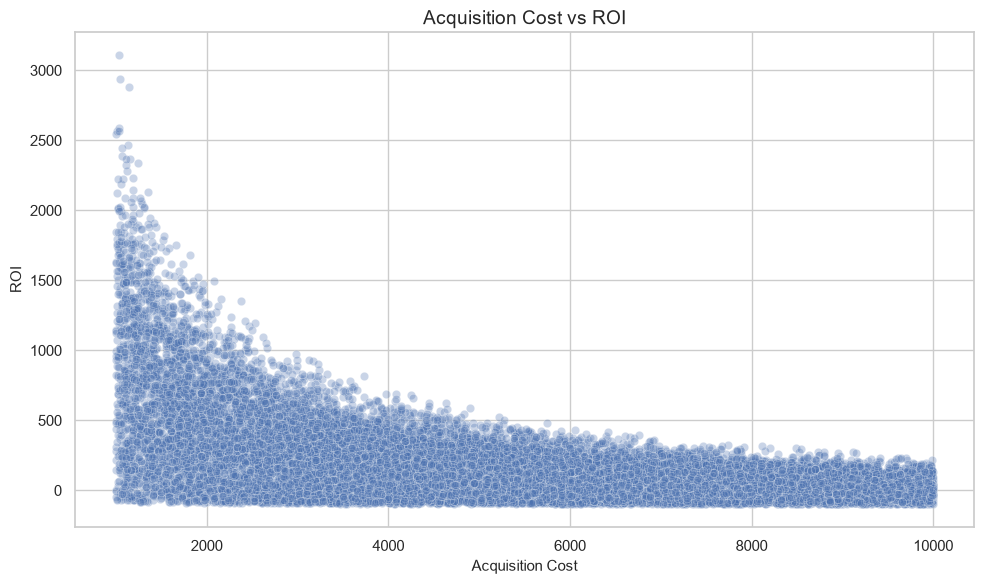

Correlation (Acquisition_Cost, ROI): -0.5747


In [44]:
# 4A. CAMPAIGN PERFORMANCE
# 4A.1 Scatter: Acquisition_Cost vs ROI
plt.figure()
sns.scatterplot(data=df, x="Acquisition_Cost", y="ROI", alpha=0.3)
plt.title("Acquisition Cost vs ROI")
plt.xlabel("Acquisition Cost")
plt.ylabel("ROI")
plt.tight_layout()
plt.show()
print("Correlation (Acquisition_Cost, ROI):",
      round(df["Acquisition_Cost"].corr(df["ROI"]), 4))


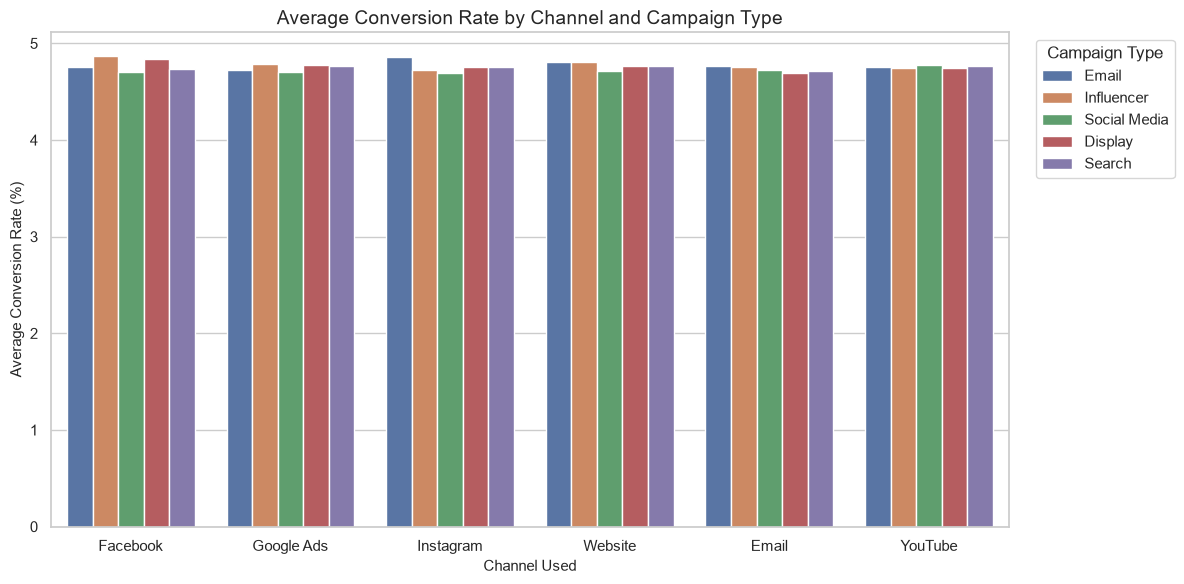

In [49]:
# 4A.2 Bar: Avg Conversion_Rate by Channel_Used, categorised by Campaign_Type
plt.figure(figsize=(12, 6))
sns.barplot(data=df, x="Channel_Used", y="Conversion_Rate",
            hue="Campaign_Type", errorbar=None)
plt.title("Average Conversion Rate by Channel and Campaign Type")
plt.xlabel("Channel Used")
plt.ylabel("Average Conversion Rate (%)")
plt.legend(title="Campaign Type", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


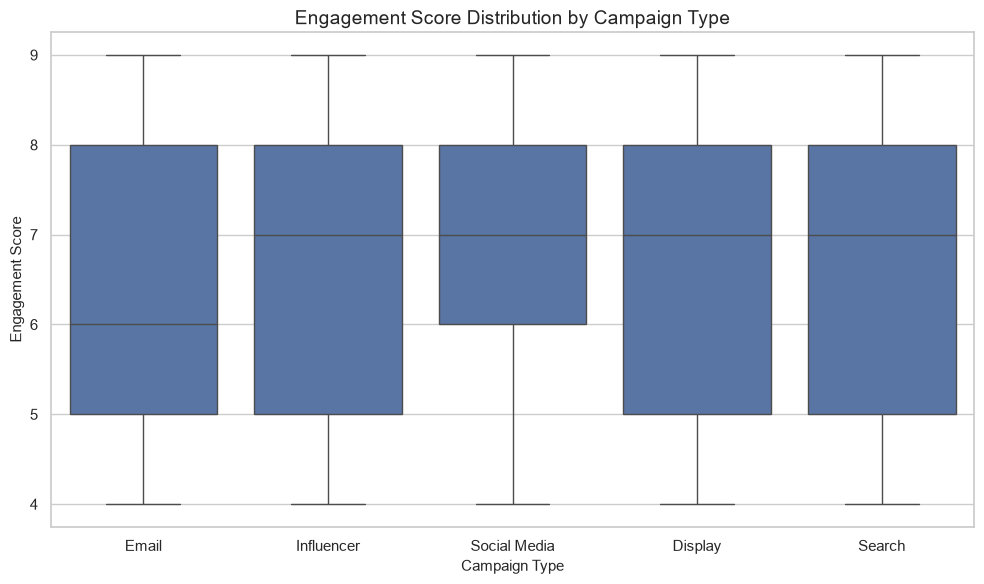

In [54]:
# 4A.3 Box: Engagement_Score across Campaign_Type
plt.figure()
sns.boxplot(data=df, x="Campaign_Type", y="Engagement_Score")
plt.title("Engagement Score Distribution by Campaign Type")
plt.xlabel("Campaign Type")
plt.ylabel("Engagement Score")
plt.tight_layout()
plt.show()


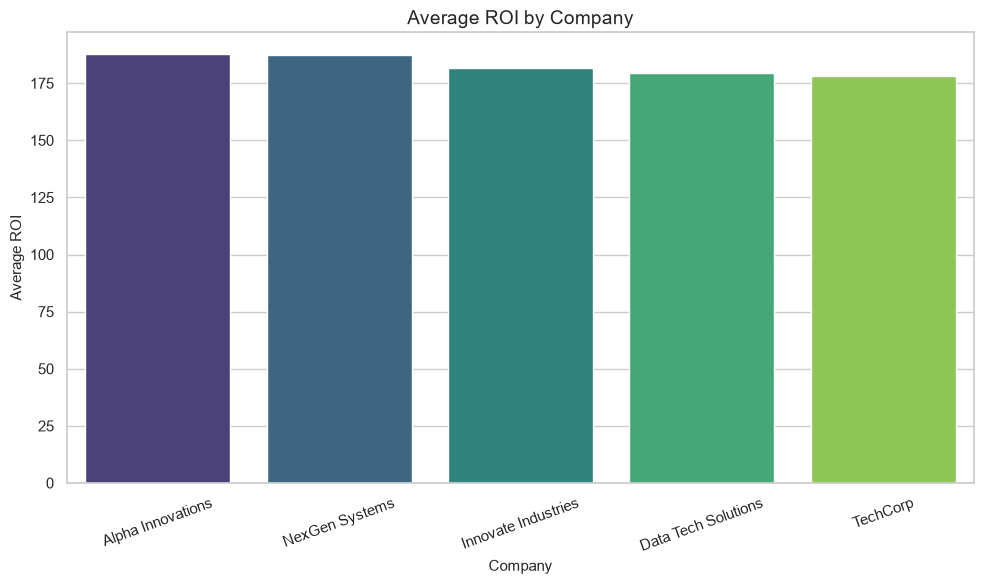

Company
Alpha Innovations      187.803
NexGen Systems         187.217
Innovate Industries    181.514
Data Tech Solutions    179.494
TechCorp               178.355
Name: ROI, dtype: float64


In [58]:
# 4A.4 Bar: Average ROI by Company
roi_company = df.groupby("Company")["ROI"].mean().sort_values(ascending=False)
plt.figure()
sns.barplot(x=roi_company.index, y=roi_company.values, palette="viridis")
plt.title("Average ROI by Company")
plt.xlabel("Company")
plt.ylabel("Average ROI")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()
print(roi_company.round(3))


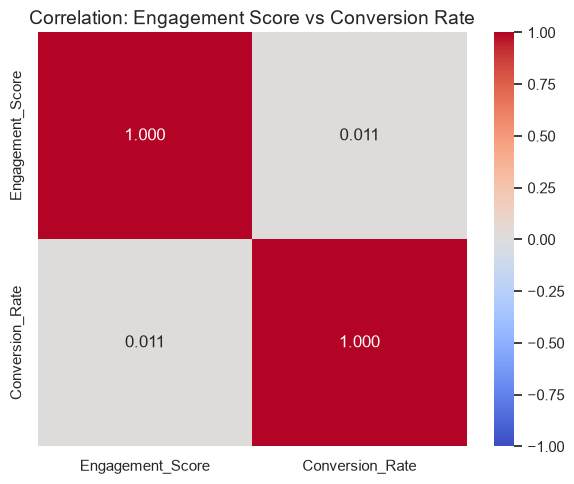

In [64]:
# 4A.5 Heatmap: Engagement_Score vs Conversion_Rate
plt.figure(figsize=(6, 5))
sns.heatmap(df[["Engagement_Score", "Conversion_Rate"]].corr(),
            annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".3f")
plt.title("Correlation: Engagement Score vs Conversion Rate")
plt.tight_layout()
plt.show()


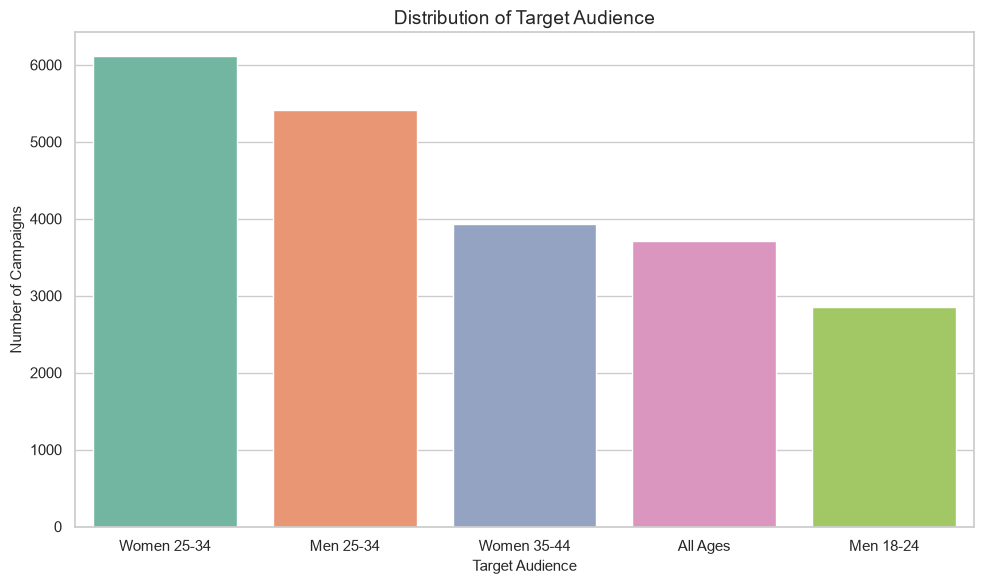

In [71]:
# 4B. CUSTOMER SEGMENTATION
# 4B.1 Count plot: Target_Audience
plt.figure()
order = df["Target_Audience"].value_counts().index
sns.countplot(data=df, x="Target_Audience", order=order, palette="Set2")
plt.title("Distribution of Target Audience")
plt.xlabel("Target Audience")
plt.ylabel("Number of Campaigns")
plt.tight_layout()
plt.show()


Best Customer_Segment per Language:
Language  Customer_Segment  Conversion_Rate
 English  Tech Enthusiasts           5.0227
  French Health & Wellness           4.6897
  German           Foodies           4.7054
Mandarin Health & Wellness           4.7561
 Spanish           Foodies           4.6636


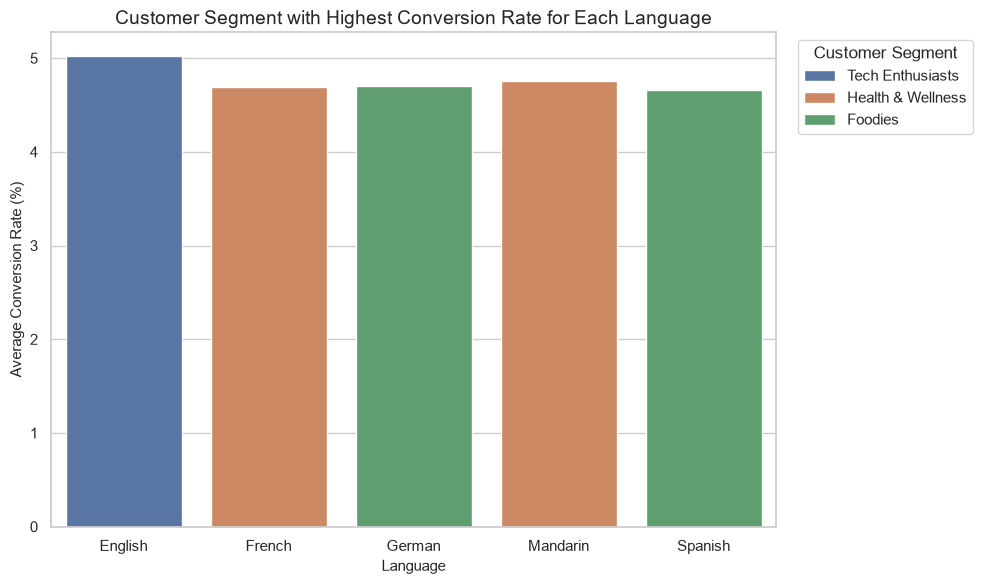

In [80]:
# 4B.2 Bar: Customer_Segment with the highest Conversion_Rate for each Language
seg_lang = (df.groupby(["Language", "Customer_Segment"])["Conversion_Rate"]
              .mean().reset_index())
best_seg = seg_lang.loc[seg_lang.groupby("Language")["Conversion_Rate"].idxmax()]
print("Best Customer_Segment per Language:")
print(best_seg.round(4).to_string(index=False))

plt.figure(figsize=(10, 6))
sns.barplot(data=best_seg, x="Language", y="Conversion_Rate",
            hue="Customer_Segment", dodge=False)
plt.title("Customer Segment with Highest Conversion Rate for Each Language")
plt.xlabel("Language")
plt.ylabel("Average Conversion Rate (%)")
plt.legend(title="Customer Segment", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


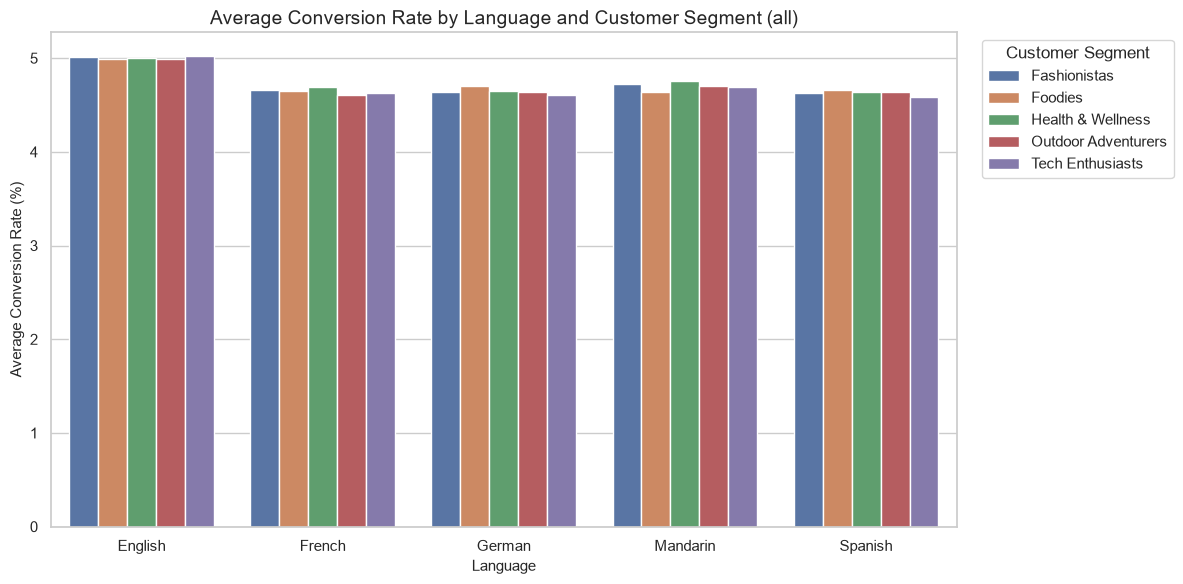

In [86]:
# (Optional full comparison of all segments in every language)
plt.figure(figsize=(12, 6))
sns.barplot(data=seg_lang, x="Language", y="Conversion_Rate", hue="Customer_Segment")
plt.title("Average Conversion Rate by Language and Customer Segment (all)")
plt.ylabel("Average Conversion Rate (%)")
plt.legend(title="Customer Segment", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


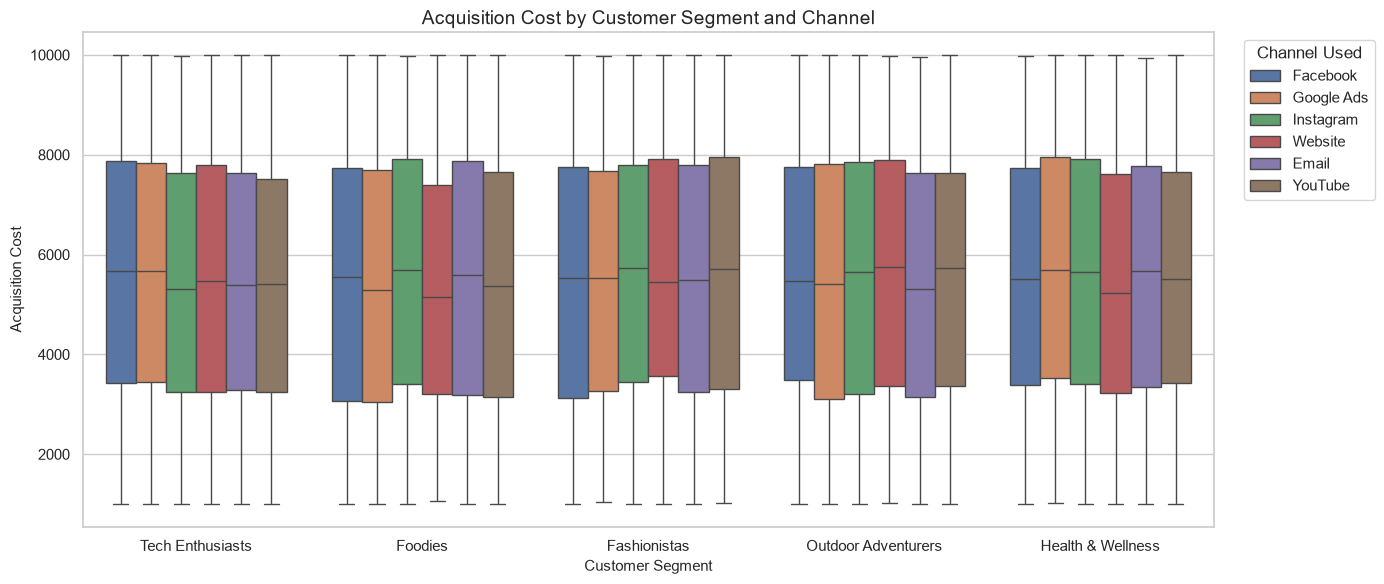

In [89]:
# 4B.3 Box: Acquisition_Cost across Customer_Segment, categorised by Channel_Used
plt.figure(figsize=(14, 6))
sns.boxplot(data=df, x="Customer_Segment", y="Acquisition_Cost", hue="Channel_Used")
plt.title("Acquisition Cost by Customer Segment and Channel")
plt.xlabel("Customer Segment")
plt.ylabel("Acquisition Cost")
plt.legend(title="Channel Used", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


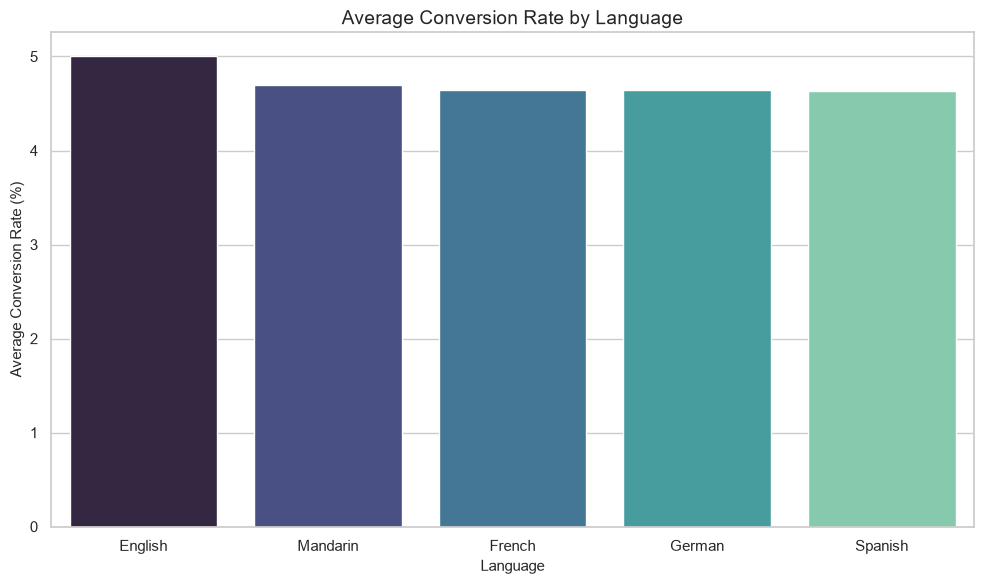

Language
English     5.0050
Mandarin    4.7013
French      4.6478
German      4.6475
Spanish     4.6305
Name: Conversion_Rate, dtype: float64


In [96]:
# 4B.4 Bar: Average Conversion_Rate by Language
conv_lang = df.groupby("Language")["Conversion_Rate"].mean().sort_values(ascending=False)
plt.figure()
sns.barplot(x=conv_lang.index, y=conv_lang.values, palette="mako")
plt.title("Average Conversion Rate by Language")
plt.xlabel("Language")
plt.ylabel("Average Conversion Rate (%)")
plt.tight_layout()
plt.show()
print(conv_lang.round(4))


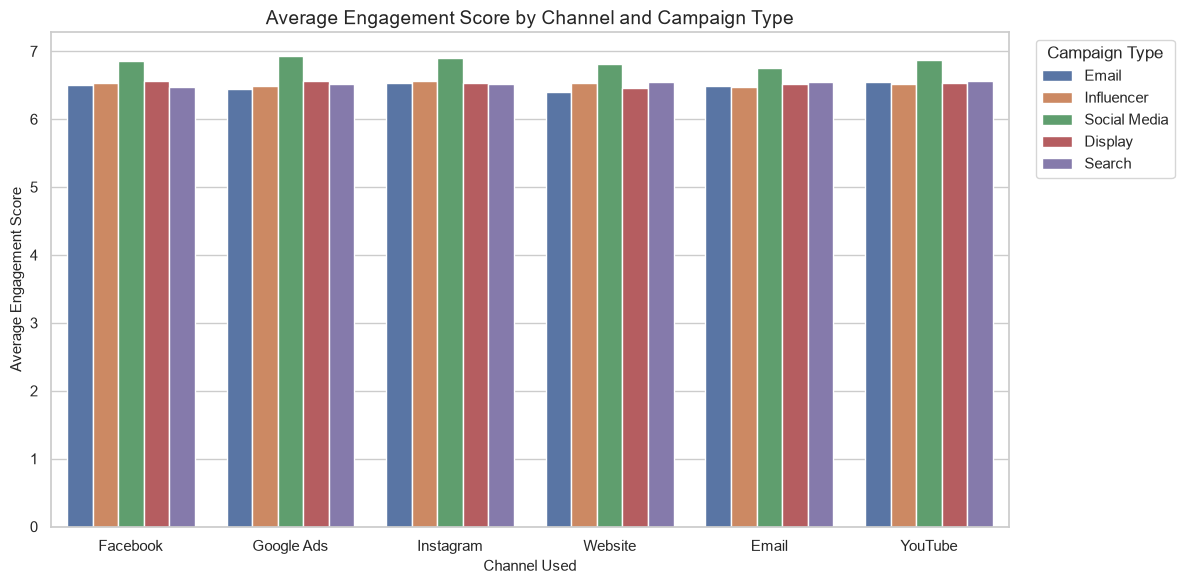

In [102]:
# 4C. CHANNEL EFFECTIVENESS
# 4C.1 Bar: Engagement_Score by Channel_Used, segmented by Campaign_Type
plt.figure(figsize=(12, 6))
sns.barplot(data=df, x="Channel_Used", y="Engagement_Score",
            hue="Campaign_Type", errorbar=None)
plt.title("Average Engagement Score by Channel and Campaign Type")
plt.xlabel("Channel Used")
plt.ylabel("Average Engagement Score")
plt.legend(title="Campaign Type", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


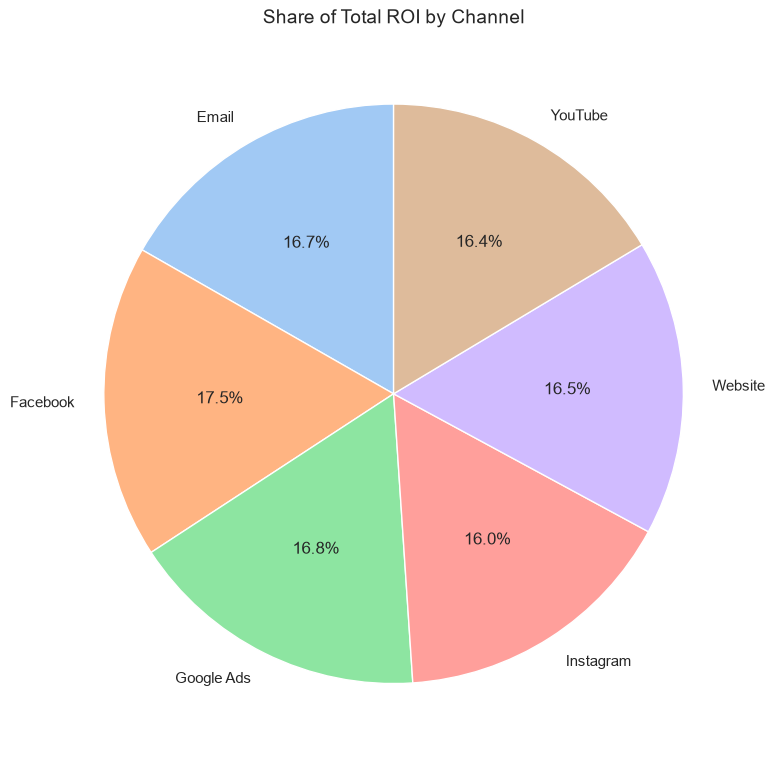

In [108]:
# 4C.2 Pie: Distribution of total ROI across Channel_Used
roi_channel = df.groupby("Channel_Used")["ROI"].sum()
plt.figure(figsize=(8, 8))
plt.pie(roi_channel, labels=roi_channel.index, autopct="%1.1f%%",
        startangle=90, colors=sns.color_palette("pastel"))
plt.title("Share of Total ROI by Channel")
plt.tight_layout()
plt.show()


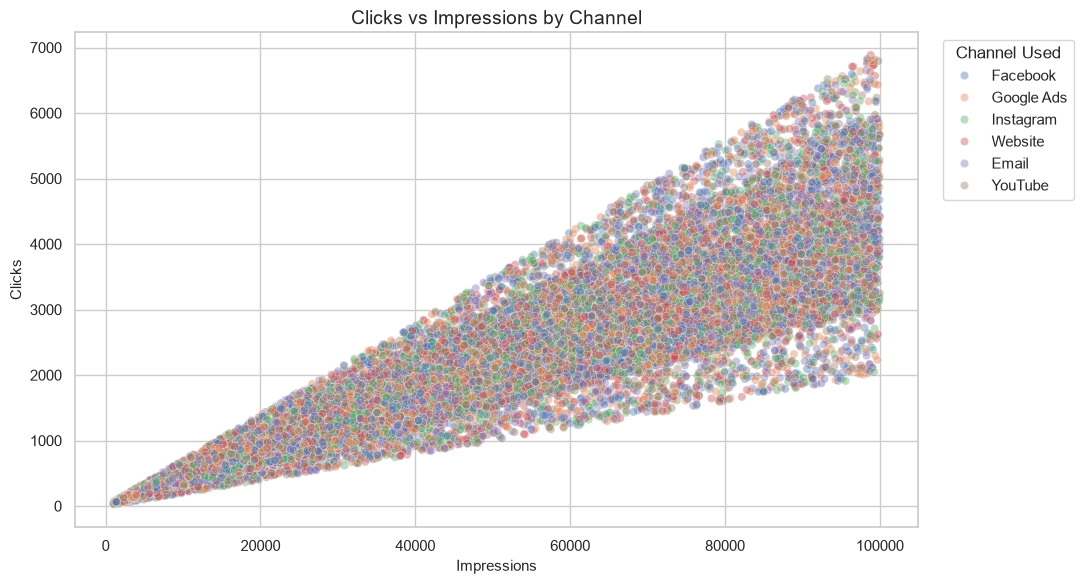

In [112]:
# 4C.3 Scatter: Clicks vs Impressions for each Channel_Used
plt.figure(figsize=(11, 6))
sns.scatterplot(data=df, x="Impressions", y="Clicks",
                hue="Channel_Used", alpha=0.4)
plt.title("Clicks vs Impressions by Channel")
plt.xlabel("Impressions")
plt.ylabel("Clicks")
plt.legend(title="Channel Used", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


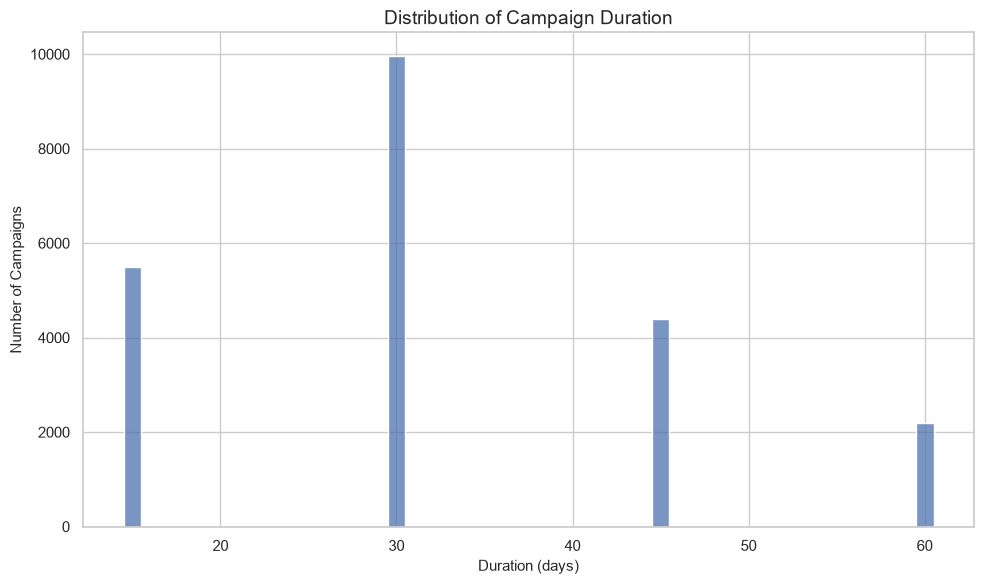

In [117]:
# 4D. TIME-BASED ANALYSIS
# 4D.1 Histogram: Duration
plt.figure()
sns.histplot(df["Duration"], bins=len(df["Duration"].unique()), discrete=True)
plt.title("Distribution of Campaign Duration")
plt.xlabel("Duration (days)")
plt.ylabel("Number of Campaigns")
plt.tight_layout()
plt.show()


In [120]:
# Helper: month column (version-safe, avoids resample alias differences)
df["Month"] = df["Date"].dt.to_period("M").dt.to_timestamp()


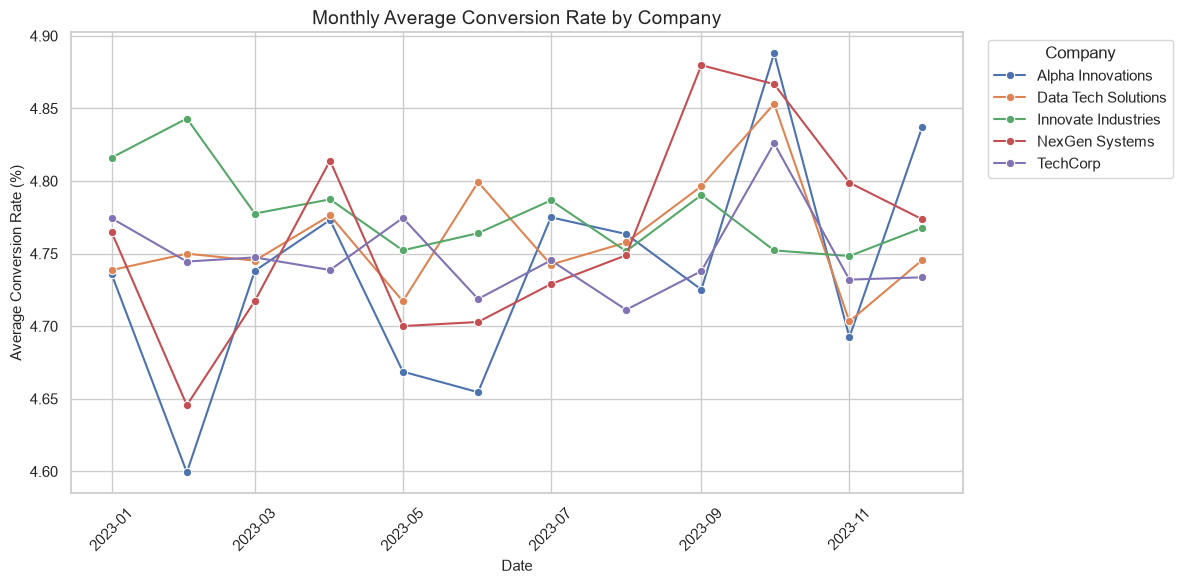

In [124]:
# 4D.2 Line: Conversion_Rate over Date for each Company (monthly average)
conv_time = df.groupby(["Month", "Company"])["Conversion_Rate"].mean().reset_index()
plt.figure(figsize=(12, 6))
sns.lineplot(data=conv_time, x="Month", y="Conversion_Rate", hue="Company", marker="o")
plt.title("Monthly Average Conversion Rate by Company")
plt.xlabel("Date")
plt.ylabel("Average Conversion Rate (%)")
plt.xticks(rotation=45)
plt.legend(title="Company", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


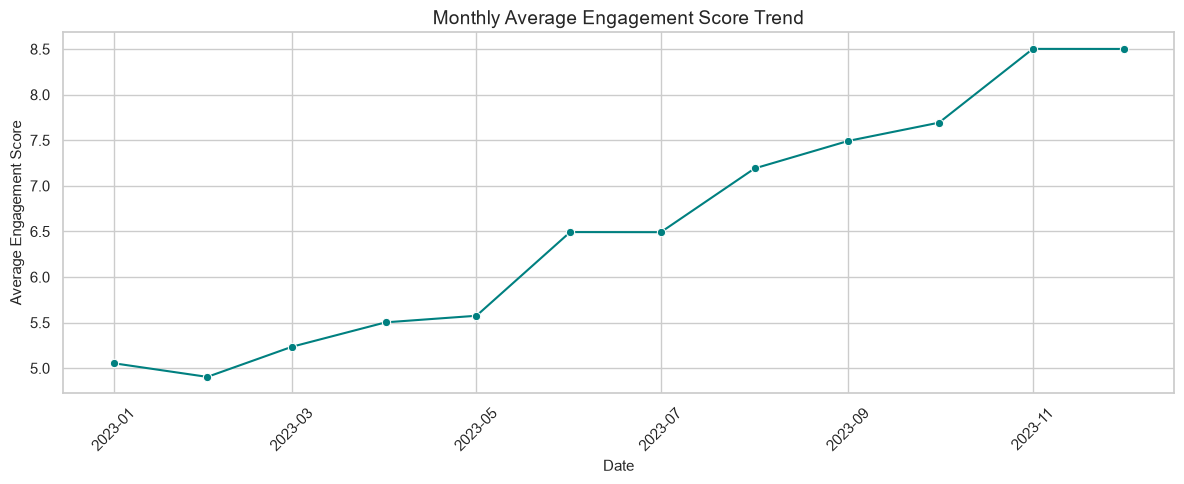

In [128]:
# 4D.3 Line: Engagement_Score trend over Date
eng_time = df.groupby("Month")["Engagement_Score"].mean().reset_index()
plt.figure(figsize=(12, 5))
sns.lineplot(data=eng_time, x="Month", y="Engagement_Score", marker="o", color="teal")
plt.title("Monthly Average Engagement Score Trend")
plt.xlabel("Date")
plt.ylabel("Average Engagement Score")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


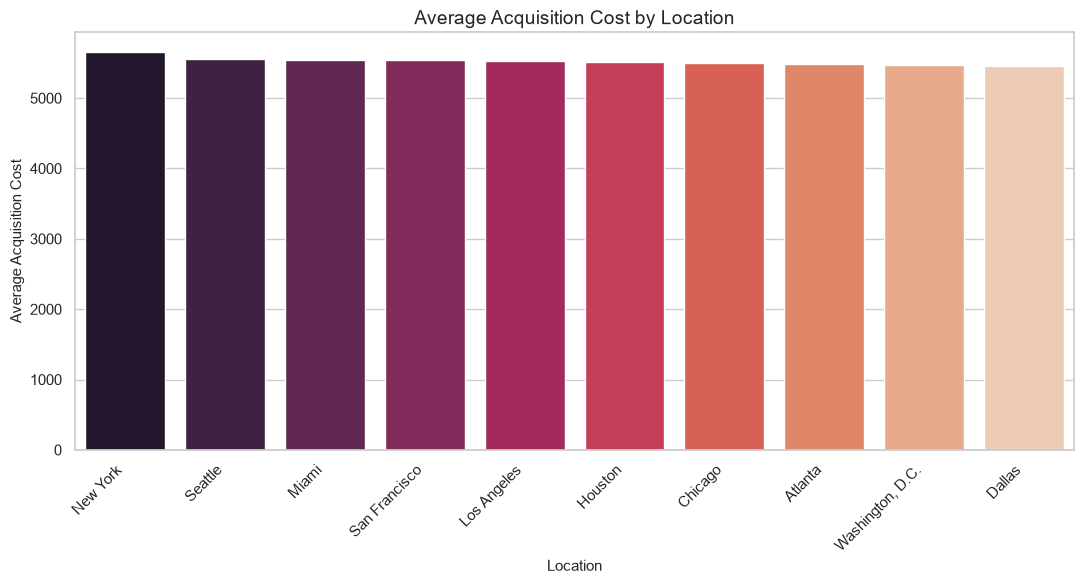

Highest average Acquisition_Cost: New York 5650.63


In [135]:
# 4E. GEOGRAPHIC ANALYSIS
# 4E.1 Bar: Location with the highest Acquisition_Cost (average)
cost_loc = df.groupby("Location")["Acquisition_Cost"].mean().sort_values(ascending=False)
plt.figure(figsize=(11, 6))
sns.barplot(x=cost_loc.index, y=cost_loc.values, palette="rocket")
plt.title("Average Acquisition Cost by Location")
plt.xlabel("Location")
plt.ylabel("Average Acquisition Cost")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
print("Highest average Acquisition_Cost:", cost_loc.idxmax(), round(cost_loc.max(), 2))


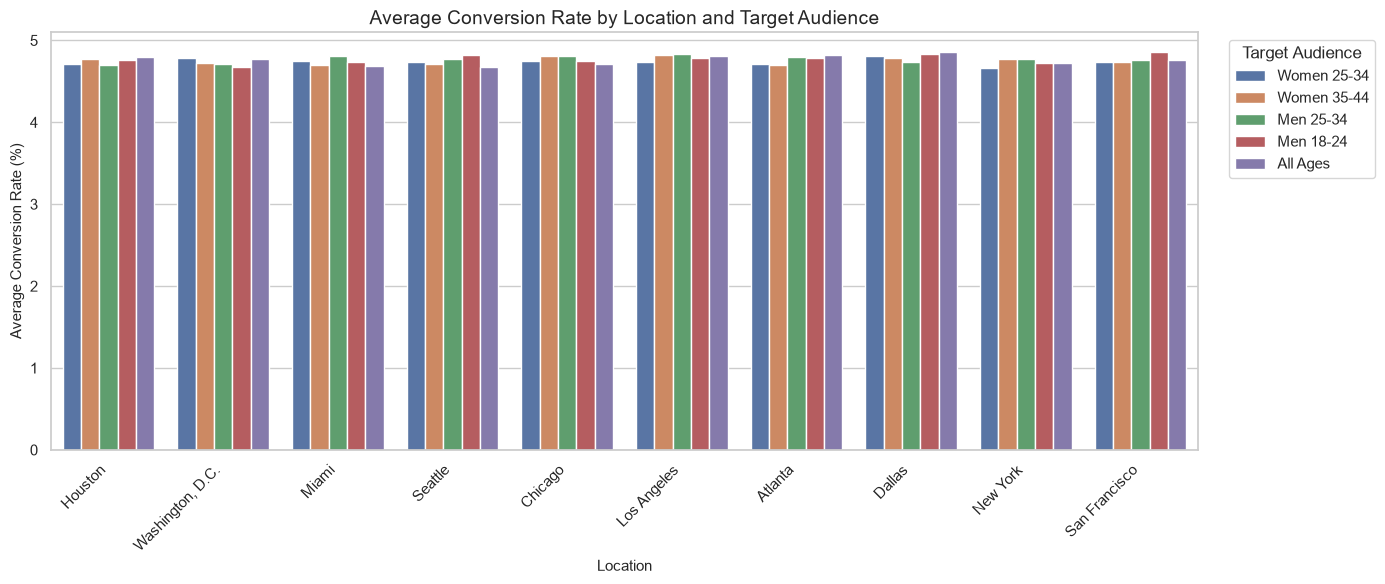

In [143]:
# 4E.2 Bar: Conversion_Rate by Location, categorised by Target_Audience
plt.figure(figsize=(14, 6))
sns.barplot(data=df, x="Location", y="Conversion_Rate",
            hue="Target_Audience", errorbar=None)
plt.title("Average Conversion Rate by Location and Target Audience")
plt.xlabel("Location")
plt.ylabel("Average Conversion Rate (%)")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Target Audience", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


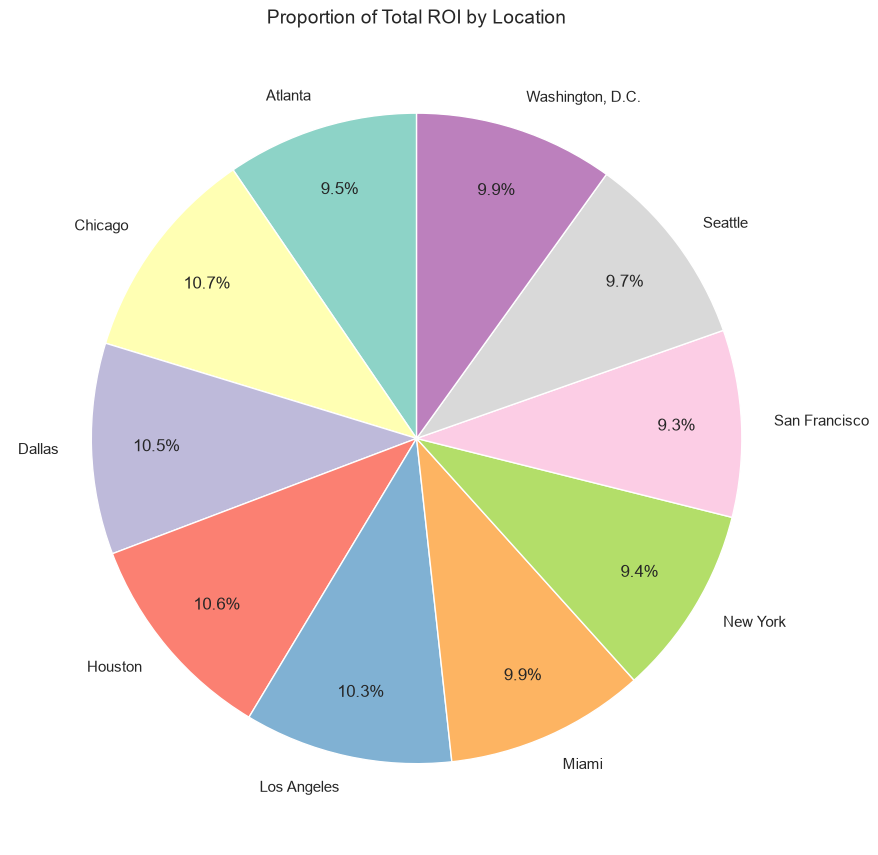

In [147]:
# 4E.3 Pie: Proportion of ROI by Location
roi_loc = df.groupby("Location")["ROI"].sum()
plt.figure(figsize=(9, 9))
plt.pie(roi_loc, labels=roi_loc.index, autopct="%1.1f%%", startangle=90,
        colors=sns.color_palette("Set3", len(roi_loc)), pctdistance=0.8)
plt.title("Proportion of Total ROI by Location")
plt.tight_layout()
plt.show()


In [159]:
# 5. KEY FINDINGS (auto-generated summary - edit with your own words)
print("=" * 60)
print("SUMMARY OF KEY FINDINGS")
print("=" * 60)
print("Top company by avg ROI       :", roi_company.idxmax(), round(roi_company.max(), 2))
print("Top language by avg conv.    :", conv_lang.idxmax(), round(conv_lang.max(), 3))
print("Top channel by total ROI     :", roi_channel.idxmax(), round(roi_channel.max(), 1))
print("Top location by total ROI    :", roi_loc.idxmax(), round(roi_loc.max(), 1))
print("Highest avg acquisition cost :", cost_loc.idxmax(), round(cost_loc.max(), 1))
print("Corr(Engagement, Conversion) :",
      round(df["Engagement_Score"].corr(df["Conversion_Rate"]), 4))
print("Corr(Acq. Cost, ROI)         :",
      round(df["Acquisition_Cost"].corr(df["ROI"]), 4))


SUMMARY OF KEY FINDINGS
Top company by avg ROI       : Alpha Innovations 187.8
Top language by avg conv.    : English 5.005
Top channel by total ROI     : Facebook 704684.8
Top location by total ROI    : Chicago 432257.4
Highest avg acquisition cost : New York 5650.6
Corr(Engagement, Conversion) : 0.0105
Corr(Acq. Cost, ROI)         : -0.5747
